# Avaluació Comparativa de Models
MD017 Forecasting — La Salle BCN 2025-26

Comparació sistemàtica de tots els models sobre el test set (2025). Mètriques: RMSE, MAE, MAPE, MASE.

El benchmark inclou tres nivells de complexitat creixent:
- **Deterministes:** MA_12, OLS_Estacional, OLS_Complet — funció fixada de *t*, sense components estocàstiques (`models/deterministic.ipynb`).
- **Estadístics:** SeasonalNaive, ETS Additiu, ETS Multiplicatiu, AutoSARIMA, TBATS — models amb estructura de dependència temporal explícita (`models/baseline.ipynb`, `models/sarima.ipynb`, `models/tbats.ipynb`).
- **Machine Learning:** LightGBM, LSTM — models d'aprenentatge supervisat (`models/lgbm.ipynb`, `models/lstm.ipynb`).

> **Prerequisit:** executar els notebooks per ordre: `models/deterministic.ipynb` → `models/baseline.ipynb` → `models/sarima.ipynb` → `models/tbats.ipynb` → `models/lgbm.ipynb` → `models/lstm.ipynb`.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import TECNOLOGIES_MODELITZABLES
from plotting import format_ts_ax

DATA_DIR    = Path('../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

## 1. Carregar tots els resultats


In [2]:
EXCLUDE = {'ensemble', 'global_lgbm'}

def _exclude(fname):
    return any(ex in fname for ex in EXCLUDE)

metric_files   = [f for f in RESULTS_DIR.glob('*_metrics.csv')
                  if f.name != 'all_metrics.csv'
                  and 'wfv' not in f.name
                  and not _exclude(f.name)]
forecast_files = [f for f in RESULTS_DIR.glob('*_forecasts.csv')
                  if 'wfv' not in f.name
                  and not _exclude(f.name)]
print(f'Fitxers de mètriques (backtest): {[f.name for f in metric_files]}')
print(f'Fitxers de forecasts (backtest): {[f.name for f in forecast_files]}')

all_metrics   = pd.concat([pd.read_csv(f) for f in metric_files],  ignore_index=True)
all_forecasts = pd.concat([pd.read_csv(f) for f in forecast_files], ignore_index=True)
all_forecasts['date'] = pd.to_datetime(all_forecasts['date'])

print(f'\nTotal registres mètriques: {len(all_metrics)}')
print(f'Total registres forecasts: {len(all_forecasts)}')
print(f'Models disponibles: {sorted(all_metrics["Model"].unique())}')

Fitxers de mètriques (backtest): ['baseline_metrics.csv', 'deterministic_metrics.csv', 'tbats_metrics.csv', 'lgbm_metrics.csv', 'lstm_metrics.csv', 'sarima_metrics.csv']
Fitxers de forecasts (backtest): ['lstm_forecasts.csv', 'baseline_forecasts.csv', 'sarima_forecasts.csv', 'tbats_forecasts.csv', 'lgbm_forecasts.csv', 'deterministic_forecasts.csv']

Total registres mètriques: 70
Total registres forecasts: 840
Models disponibles: ['AutoSARIMA', 'ETS_Additiu', 'ETS_Multiplicatiu', 'LSTM', 'LightGBM', 'MA_12', 'OLS_Complet', 'OLS_Estacional', 'SeasonalNaive', 'TBATS']


## 2. Visió global

Rànquing global (MASE mig — totes les tecnologies):


,RMSE,MAE,MAPE,MASE,Rànquing MASE
Model,,,,,
AutoSARIMA,425.25,367.69,19.44,1.49,1
ETS_Additiu,435.56,367.87,19.93,1.55,2
TBATS,418.77,352.45,20.58,1.59,3
LSTM,473.30,405.54,22.70,1.77,4
OLS_Estacional,535.41,473.04,24.52,1.87,5
OLS_Complet,555.00,491.41,24.66,1.90,6
ETS_Multiplicatiu,588.80,540.98,25.24,1.94,7
SeasonalNaive,645.03,587.54,25.91,2.06,8
MA_12,695.12,601.81,25.37,2.09,9


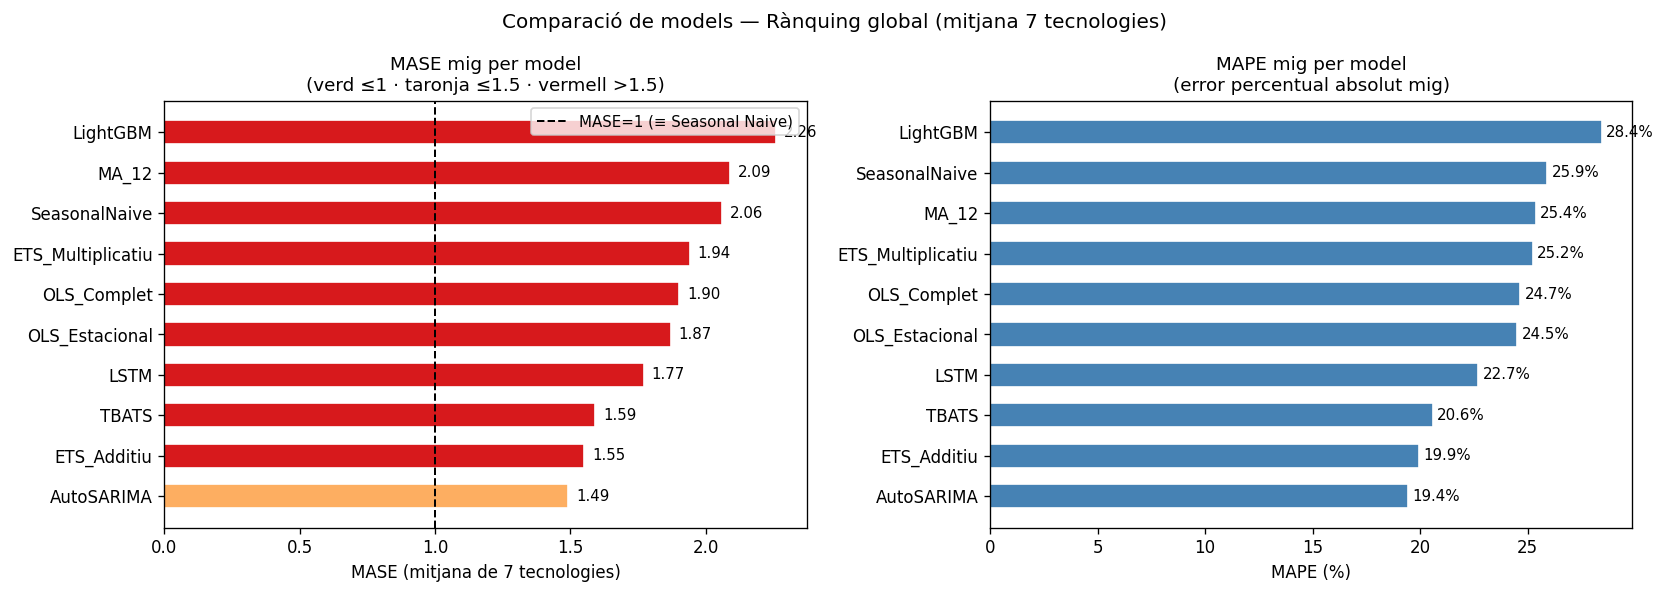

In [3]:
summary = (
    all_metrics
    .groupby('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .mean()
    .round(2)
    .sort_values('MASE')
)
summary['Rànquing MASE'] = range(1, len(summary) + 1)
print('Rànquing global (MASE mig — totes les tecnologies):')
display(summary)

# Gràfic comparatiu: MASE i MAPE per model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

summary_mase = summary.sort_values('MASE')
colors_mase = ['#1a9641' if v <= 1.0 else '#fdae61' if v <= 1.5 else '#d7191c'
               for v in summary_mase['MASE']]
axes[0].barh(summary_mase.index, summary_mase['MASE'],
             color=colors_mase, edgecolor='white', height=0.6)
axes[0].axvline(1.0, color='black', ls='--', lw=1.2, label='MASE=1 (≡ Seasonal Naive)')
axes[0].set_title('MASE mig per model\n(verd ≤1 · taronja ≤1.5 · vermell >1.5)', fontsize=11)
axes[0].set_xlabel('MASE (mitjana de 7 tecnologies)')
axes[0].legend(fontsize=9)
for i, v in enumerate(summary_mase['MASE']):
    axes[0].text(v + 0.03, i, f'{v:.2f}', va='center', fontsize=9)

summary_mape = summary.sort_values('MAPE')
axes[1].barh(summary_mape.index, summary_mape['MAPE'],
             color='steelblue', edgecolor='white', height=0.6)
axes[1].set_title('MAPE mig per model\n(error percentual absolut mig)', fontsize=11)
axes[1].set_xlabel('MAPE (%)')
for i, v in enumerate(summary_mape['MAPE']):
    axes[1].text(v + 0.2, i, f'{v:.1f}%', va='center', fontsize=9)

plt.suptitle('Comparació de models — Rànquing global (mitjana 7 tecnologies)', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_17_model_ranking.png', bbox_inches='tight')
plt.show()

### Interpretació del rànquing global

Un MASE > 1 per a tots els models pot semblar, a primera vista, decebedor. Cal posar-ho en perspectiva: la mitjana global queda inflada per la tecnologia Gasolina/Elèctric Endollable, amb MAPEs superiors al 40% deguts a una dinàmica de creixement massa irregular perquè cap model la capturi bé. Si s'exclou aquesta tecnologia, els millors models per a sèries com Gasolina/Elèctric i Gasolina Mild Hybrid sí que prediuen per sota de MASE=1.

AutoSARIMA encapçala el rànquing amb un MASE mig de 1.49, seguit d'ETS Additiu (1.55) i TBATS (1.59). Cal llegir aquest rànquing com una mesura de consistència, no de dominança: AutoSARIMA no és el millor model per a la majoria de tecnologies individuals, però és el que mai no s'enfonsa. La secció 3 desglossa el millor model per cada tecnologia, on el patró és diferent: ETS Multiplicatiu guanya a les sèries de creixement accelerat, i TBATS és el millor per a la sèrie Total. Els models deterministes OLS_Estacional (1.87) i OLS_Complet (1.90) es situen a la meitat del rànquing, per davant d'ETS Multiplicatiu (1.94) i SeasonalNaive (2.06), cosa que mostra que una regressió lineal ben especificada supera els baselines simples però queda lluny dels millors estadístics. LightGBM és el pitjor del benchmark estadístic i ML (2.26): amb N≈84 mostres de train, el gradient boosting no té prou dades per generalitzar l'estacionalitat. MA_12, sense cap component estacional, obté un MASE de 2.09 lleugerament per sota de LightGBM.

### Comparació visual — sèrie Total

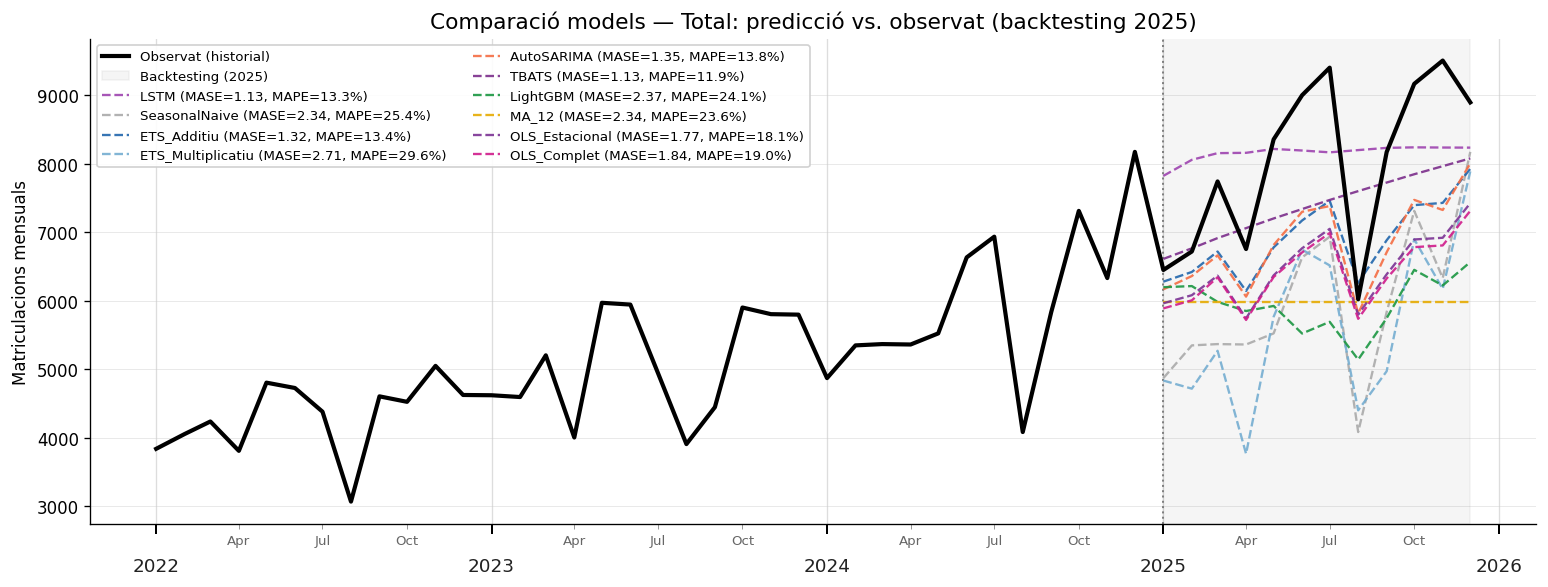

In [4]:
import matplotlib.dates as mdates

tech = 'Total'
sub = all_forecasts[all_forecasts['Tecnologia'] == tech].copy()

pivot_train_ev = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test_ev  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)

palette = {
    'SeasonalNaive':    '#aaaaaa',
    'ETS_Additiu':      '#2166ac',
    'ETS_Multiplicatiu':'#74add1',
    'AutoSARIMA':       '#f46d43',
    'LightGBM':         '#1a9641',
    'LSTM':             '#9e44b0',
    'TBATS':            '#7b2d8b',
    'MA_12':            '#e6ab02',
    'OLS_Estacional':   '#7b3294',
    'OLS_Complet':      '#d01c8b',
}

fig, ax = plt.subplots(figsize=(13, 5))

y_train_plot = pivot_train_ev[tech].iloc[-36:]
y_test_plot  = pivot_test_ev[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='black', lw=2.5,
        label='Observat (historial)', zorder=10)

ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1],
           alpha=0.08, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1.2)

for model_name in sub['Model'].unique():
    msub = sub[sub['Model'] == model_name].sort_values('date')
    row = all_metrics[(all_metrics['Model'] == model_name) &
                      (all_metrics['Tecnologia'] == tech)]
    if len(row):
        label = f"{model_name} (MASE={row['MASE'].values[0]:.2f}, MAPE={row['MAPE'].values[0]:.1f}%)"
    else:
        label = model_name
    ax.plot(msub['date'], msub['predicted'],
            color=palette.get(model_name, '#888888'),
            lw=1.4, ls='--', label=label, alpha=0.9)

ax.set_title(f'Comparació models — {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, loc='upper left', ncol=2, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_16_comparison_total.png', bbox_inches='tight')
plt.show()

La gràfica del Total il·lustra una tensió interessant entre forma i nivell. TBATS i LSTM, que obtenen els millors MASE per al Total (tots dos 1.13), prediuen una corba relativament plana i suavitzada: encerten bé el nivell general però subestimen els pics de primavera i tardor i les valls d'agost. AutoSARIMA, tot i tenir un MASE més alt (1.35), segueix millor la forma estacional, però acumula errors en els mesos extrems perquè el nivell predit és massa baix. ETS Additiu presenta un comportament similar a AutoSARIMA, lleugerament per sota del nivell real.

ETS Multiplicatiu és el que s'allunya més en la gràfica, especialment als mesos de creixement fort, consistent amb el seu MASE global de 1.94. Els models deterministes (OLS_Estacional, OLS_Complet) extrapolant la tendència lineal produeixen una corba amb pendent correcte però sense la curvatura de l'acceleració del 2025; queden per sota de la realitat però per damunt dels pitjors baselines. LightGBM mostra prediccions poc modulades amb molt poc contrast estacional. En conjunt, la figura confirma que el 2025 va créixer per sobre del que qualsevol model podia anticipar: la diferència entre totes les corbes i la línia observada és sistemàticament positiva (tots subestimen), cosa que apunta a una acceleració estructural del mercat, no a errors de modelització individuals.

## 3. Anàlisi per tecnologia

### Mètriques per tecnologia (taula + bar-chart)

Per a cada tecnologia (i per al Total), comparem els models en les 4 mètriques (RMSE, MAE, MAPE, MASE). La taula destaca el millor model de cada columna. El bar-chart de 4 subplots permet veure d'un cop d'ull la magnitud relativa de cada model en cadascuna de les mètriques.


— Elèctric —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Multiplicatiu,493.560000,403.550000,22.010000,1.220000
ETS_Additiu,493.840000,408.500000,21.880000,1.230000
OLS_Estacional,493.830000,408.470000,21.880000,1.230000
OLS_Complet,521.130000,436.320000,23.480000,1.320000
AutoSARIMA,507.550000,453.760000,25.510000,1.370000
TBATS,561.010000,466.750000,24.700000,1.410000
LSTM,623.780000,527.970000,28.110000,1.600000
LightGBM,607.460000,544.890000,30.050000,1.650000
MA_12,679.740000,591.170000,31.910000,1.790000


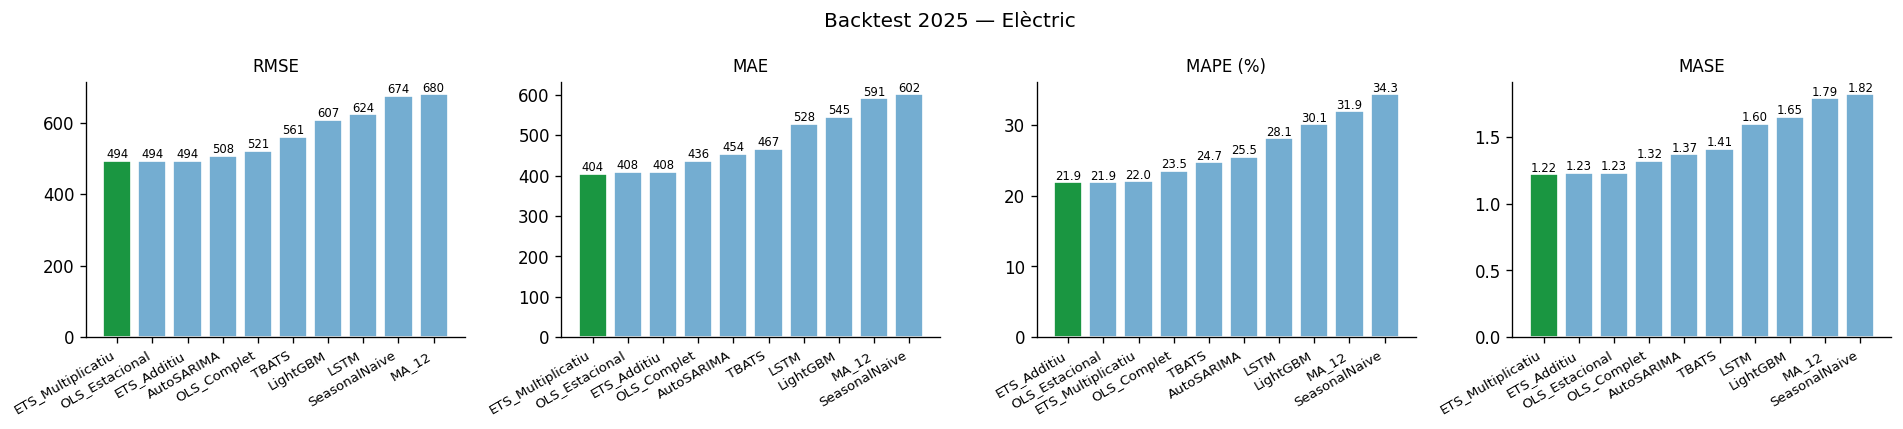


— Gasolina Mild Hybrid —


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,198.670000,146.310000,7.690000,0.560000
TBATS,234.530000,178.030000,9.400000,0.680000
ETS_Multiplicatiu,220.310000,186.850000,8.530000,0.720000
ETS_Additiu,279.930000,205.750000,10.970000,0.790000
OLS_Estacional,290.830000,254.020000,11.840000,0.970000
LSTM,319.560000,264.040000,12.800000,1.010000
OLS_Complet,307.740000,274.330000,12.700000,1.050000
SeasonalNaive,446.720000,387.830000,18.050000,1.490000
LightGBM,441.600000,393.320000,17.580000,1.510000


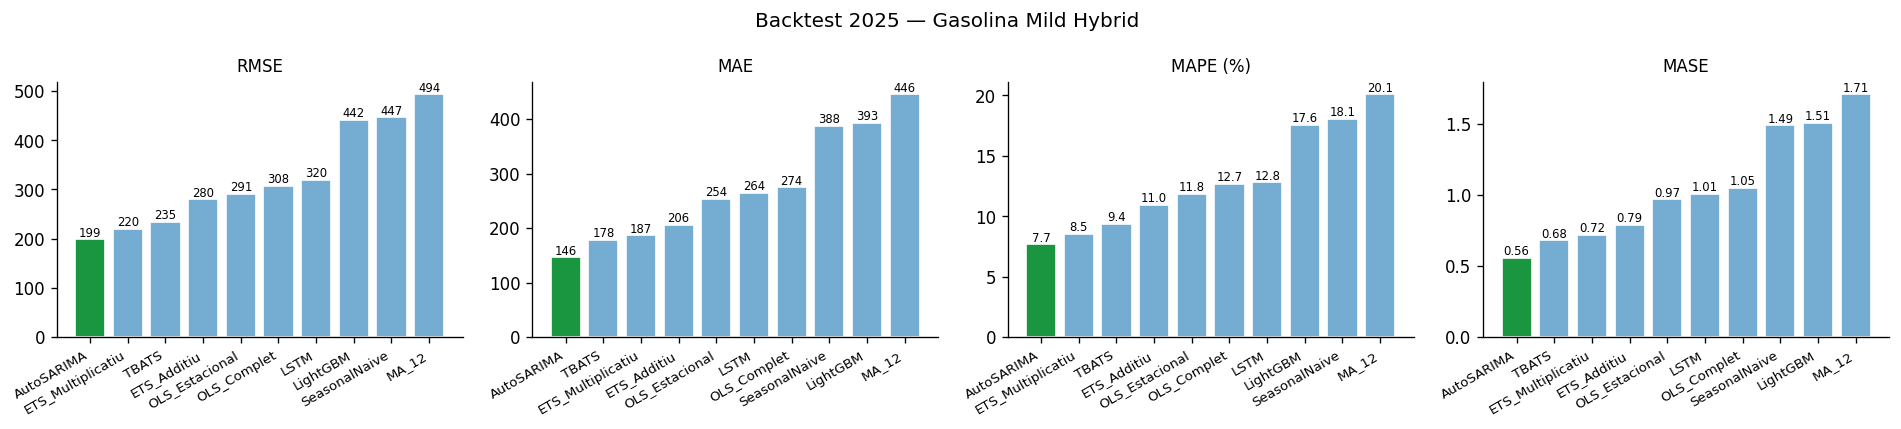


— Gasolina/Elèctric —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Multiplicatiu,188.530000,157.740000,6.190000,0.550000
ETS_Additiu,211.900000,169.600000,7.180000,0.600000
AutoSARIMA,212.300000,170.510000,6.980000,0.600000
TBATS,246.970000,190.290000,8.230000,0.670000
LSTM,428.840000,366.660000,15.910000,1.290000
SeasonalNaive,455.430000,379.670000,15.060000,1.330000
MA_12,527.630000,438.940000,16.310000,1.540000
OLS_Complet,525.490000,466.120000,17.540000,1.640000
OLS_Estacional,553.140000,504.970000,19.190000,1.770000


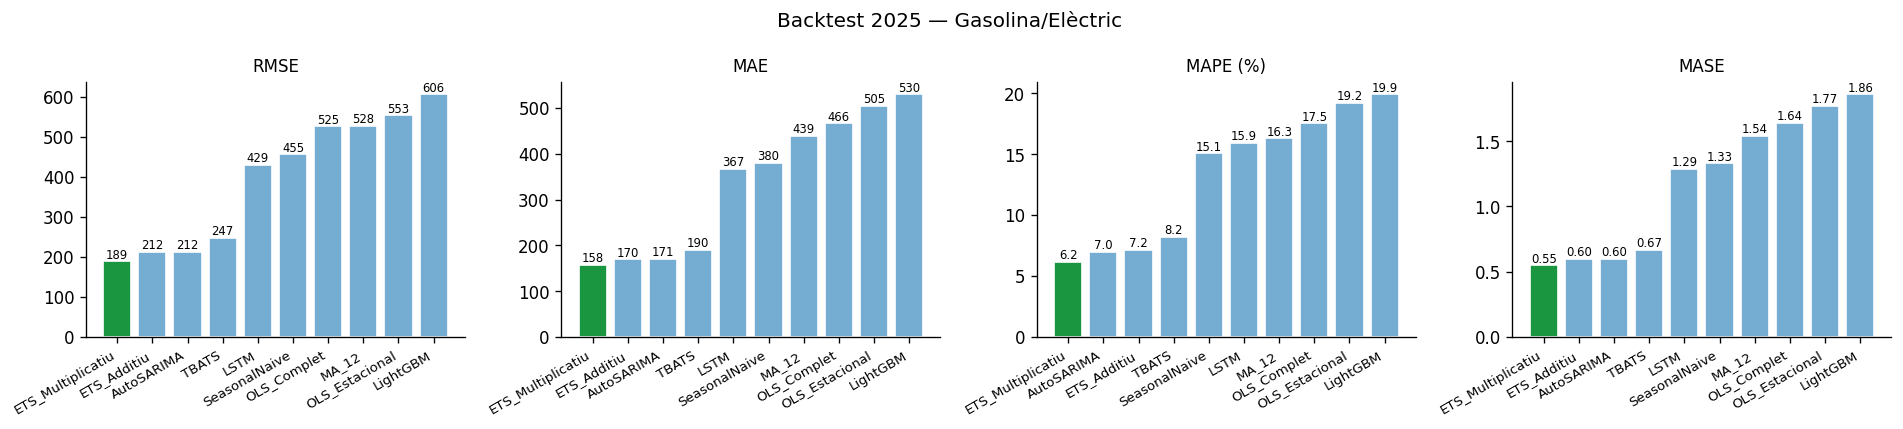


— Gasolina/Elèctric Endollable —


,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Estacional,585.630000,511.830000,35.940000,3.970000
OLS_Complet,641.200000,563.480000,39.480000,4.370000
AutoSARIMA,650.910000,580.040000,41.080000,4.500000
ETS_Additiu,658.590000,582.430000,40.890000,4.520000
TBATS,668.740000,599.200000,42.540000,4.650000
ETS_Multiplicatiu,685.590000,614.790000,43.770000,4.770000
LSTM,738.280000,648.510000,45.150000,5.030000
SeasonalNaive,724.480000,655.580000,47.100000,5.090000
MA_12,746.160000,655.900000,45.660000,5.090000


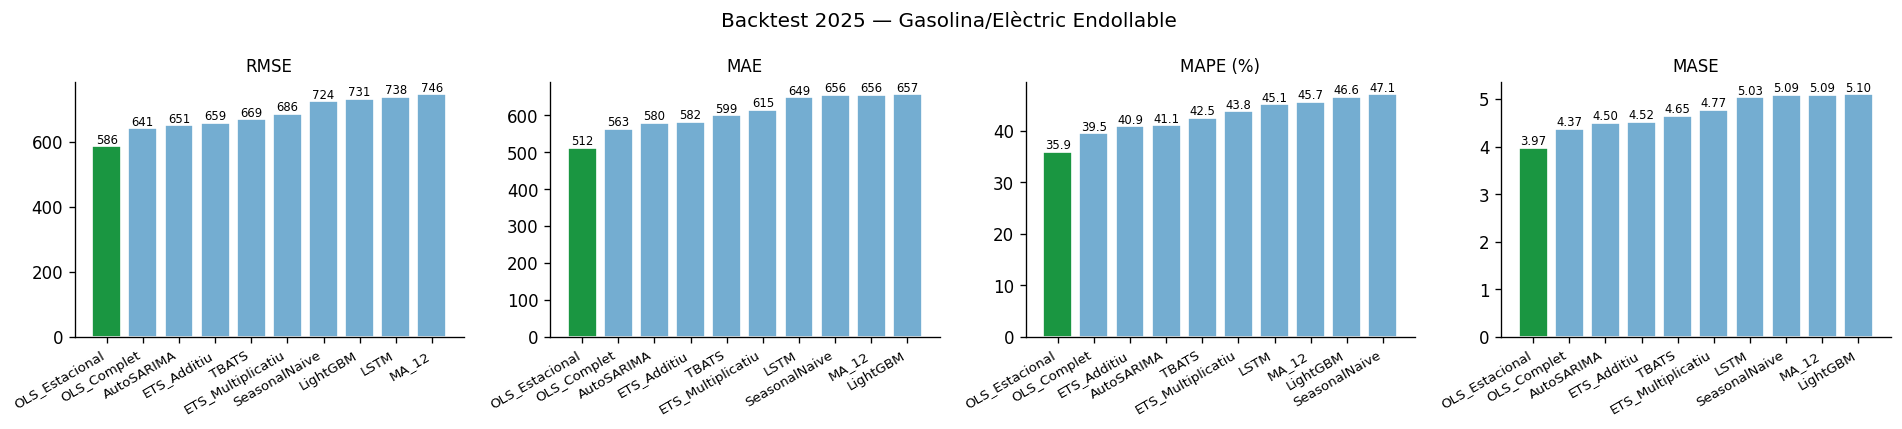


— Diesel Mild Hybrid —


,RMSE,MAE,MAPE,MASE
Model,,,,
LSTM,41.210000,32.540000,11.270000,0.530000
MA_12,41.250000,32.850000,11.430000,0.540000
TBATS,40.040000,32.830000,11.690000,0.540000
AutoSARIMA,42.820000,34.330000,12.110000,0.560000
LightGBM,47.460000,36.660000,12.900000,0.600000
SeasonalNaive,54.920000,39.330000,13.060000,0.640000
ETS_Additiu,55.070000,44.900000,16.830000,0.740000
ETS_Multiplicatiu,57.220000,46.640000,16.670000,0.760000
OLS_Estacional,88.010000,79.410000,29.890000,1.300000


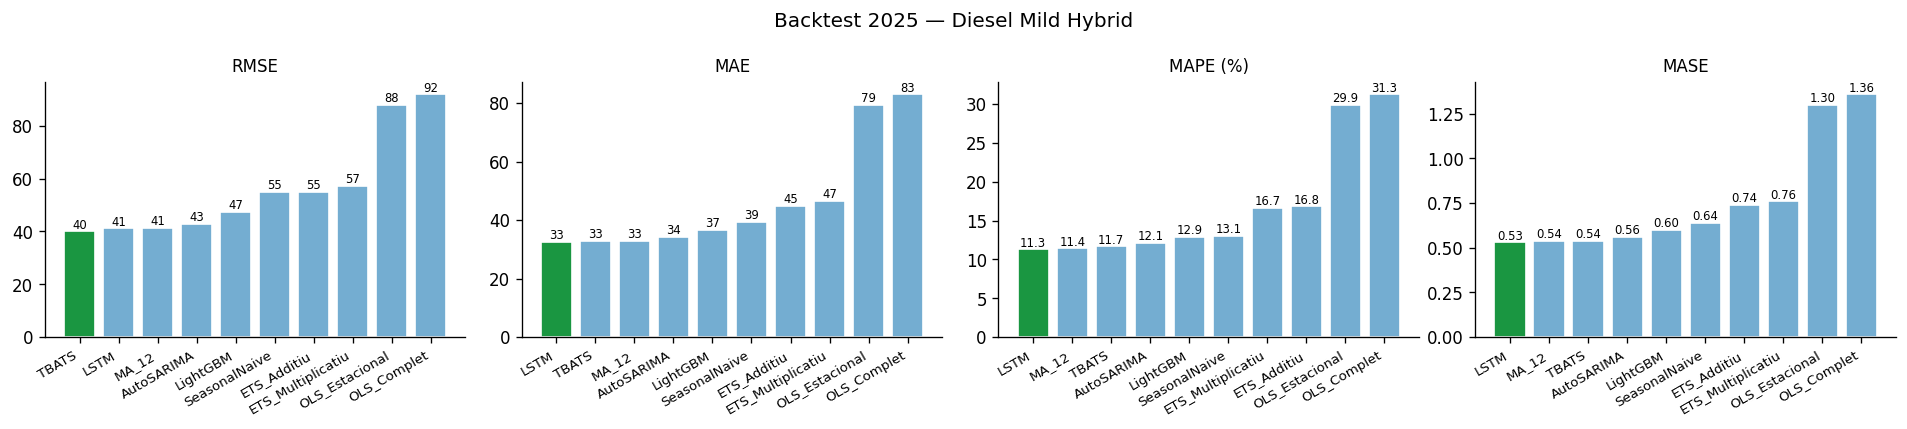


— Diesel/Elèctric Endollable —


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,16.000000,12.450000,28.900000,1.500000
MA_12,17.810000,13.710000,28.590000,1.650000
ETS_Additiu,18.540000,13.850000,28.350000,1.670000
SeasonalNaive,19.480000,14.250000,28.350000,1.720000
OLS_Complet,19.040000,14.480000,29.230000,1.750000
LSTM,18.210000,14.790000,32.370000,1.790000
OLS_Estacional,21.360000,17.060000,34.780000,2.060000
TBATS,21.230000,17.270000,35.570000,2.080000
LightGBM,27.450000,22.940000,48.000000,2.770000


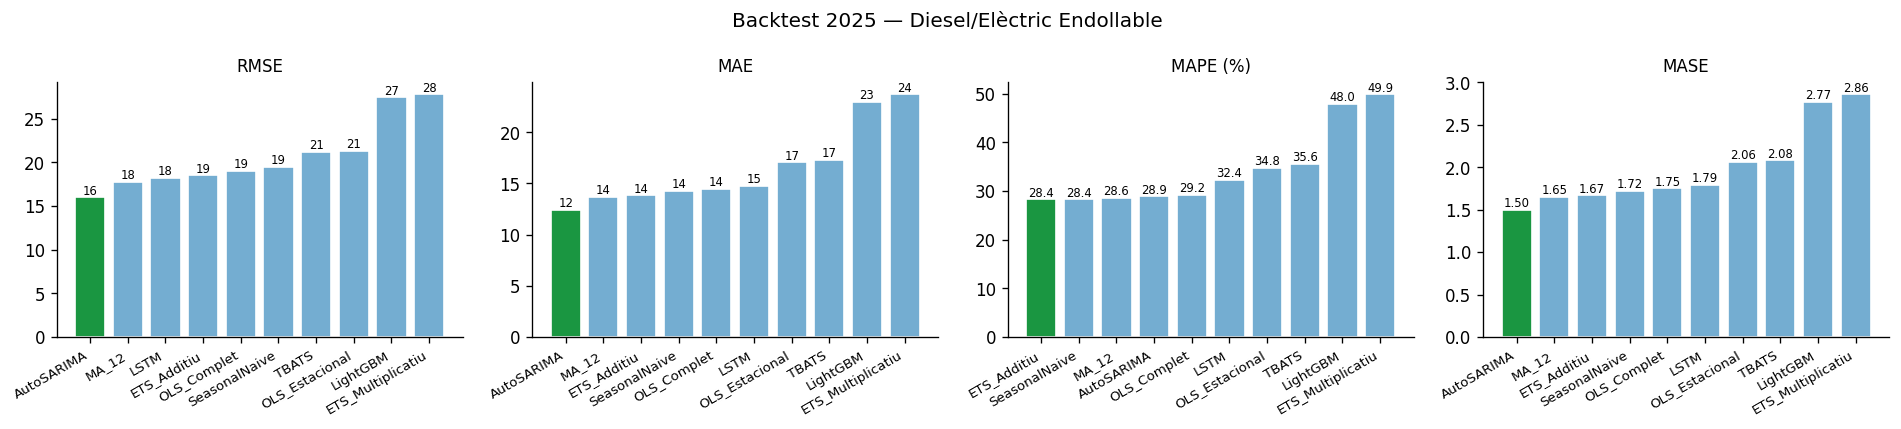


— Total —


,RMSE,MAE,MAPE,MASE
Model,,,,
TBATS,1158.850000,982.760000,11.890000,1.130000
LSTM,1143.190000,984.280000,13.250000,1.130000
ETS_Additiu,1331.060000,1150.070000,13.420000,1.320000
AutoSARIMA,1348.530000,1176.450000,13.800000,1.350000
OLS_Estacional,1715.070000,1535.510000,18.130000,1.770000
OLS_Complet,1778.480000,1602.120000,18.960000,1.840000
SeasonalNaive,2139.760000,2034.580000,25.440000,2.340000
MA_12,2359.610000,2034.580000,23.580000,2.340000
LightGBM,2350.120000,2056.620000,24.120000,2.370000


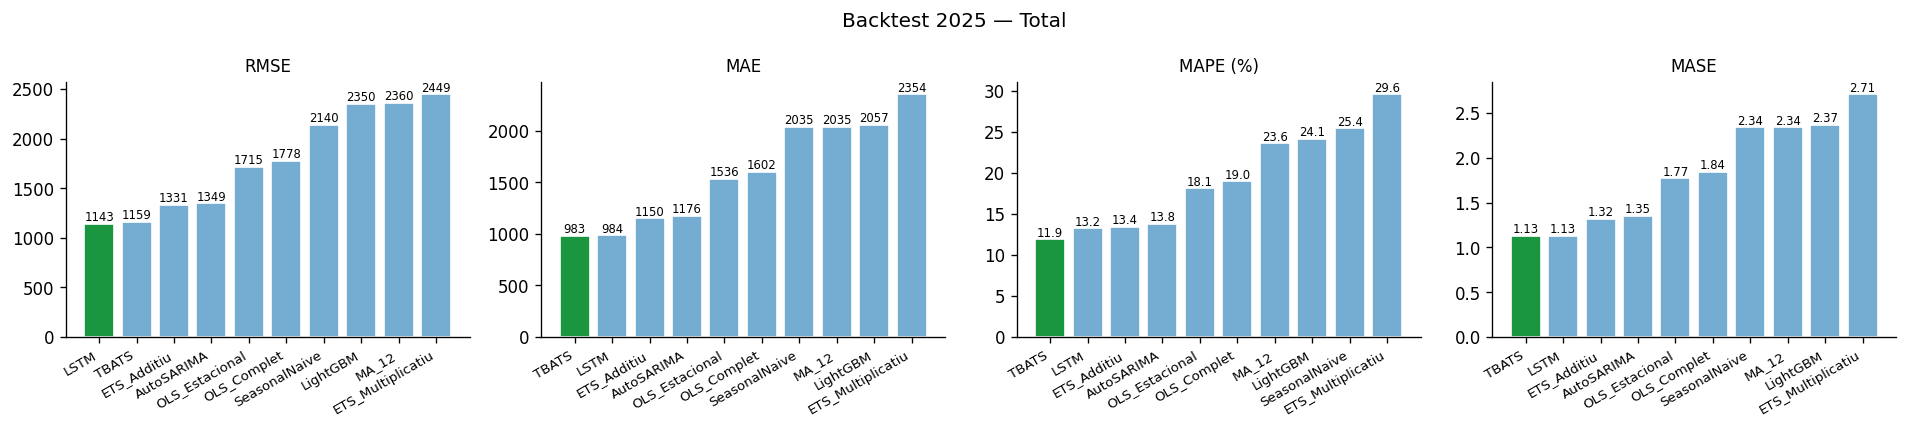

In [5]:
import re
METRICS_4 = ['RMSE', 'MAE', 'MAPE', 'MASE']

def slugify(s):
    s = re.sub(r'[^\w]+', '_', s.lower())
    return s.strip('_')

def per_tech_tables_and_bars(metrics_df, tag, save_prefix, suptitle_prefix):
    """Per cada tech: imprimeix taula (4 metrics, highlight min) i guarda bar-chart 1x4."""
    for letter, tech in zip('abcdefgh', TECNOLOGIES):
        sub = (metrics_df[metrics_df['Tecnologia'] == tech]
               .set_index('Model')[METRICS_4].round(2)
               .sort_values('MASE'))
        if len(sub) == 0:
            continue
        print(f'\n— {tech} —')
        display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#1a9641'))

        fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
        for ax, metric in zip(axes, METRICS_4):
            order = sub[metric].sort_values().index.tolist()
            colors_bar = ['#1a9641' if i == 0 else '#74add1' for i in range(len(order))]
            ax.bar(range(len(order)), sub.loc[order, metric].values,
                   color=colors_bar, edgecolor='white')
            ax.set_xticks(range(len(order)))
            ax.set_xticklabels(order, rotation=30, ha='right', fontsize=8)
            ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ''), fontsize=10)
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            for i, v in enumerate(sub.loc[order, metric].values):
                ax.text(i, v, f'{v:.1f}' if metric == 'MAPE' else f'{v:.0f}' if metric in ('RMSE','MAE') else f'{v:.2f}',
                        ha='center', va='bottom', fontsize=7)
        plt.suptitle(f'{suptitle_prefix} — {tech}', fontsize=12)
        plt.tight_layout()
        plt.savefig(FIGURES_DIR / f'fig_{save_prefix}_{letter}_{slugify(tech)}.png',
                    bbox_inches='tight')
        plt.show()
        plt.close(fig)

per_tech_tables_and_bars(all_metrics, 'backtest', '15', 'Backtest 2025')

Cap model no guanya a totes les tecnologies alhora, i el patró de guanyadors té una lectura clara. ETS Multiplicatiu és el millor per a Elèctric i Gasolina/Elèctric, les dues tecnologies on l'amplitud de l'estacionalitat creix proporcionalment al nivell de la sèrie. AutoSARIMA domina les tecnologies amb dinàmica més estable i lineal (Gasolina Mild Hybrid, Diesel/Elèctric Endollable). El LSTM queda primer a Diesel Mild Hybrid per centèsimes, sense significació pràctica amb 12 observacions de test. A Gasolina/Elèctric Endollable, OLS_Estacional "guanya" amb MASE=3.97, però aquesta victòria és per eliminació: tots els models fallen estrepitosament en aquesta sèrie i el OLS és simplement el menys dolent — cap model pot anticipar el +102% de 2025.

Per a la sèrie Total, TBATS (1.13) i LSTM (1.13) superen clarament AutoSARIMA (1.35): la transformació Box-Cox de TBATS estabilitza millor la variança creixent de l'agregat, i la memòria seqüencial del LSTM capta la dinàmica del nivell total amb prou regularitat. AutoSARIMA lidera el rànquing global no perquè guanyi la majoria de tecnologies individuals, sinó perquè és el model més consistent: ETS Multiplicatiu guanya 2 techs però s'enfonsa al Total (MASE=2.71) i a Diesel/Elèctric Endollable (2.86), i TBATS pateix també a Diesel/Elèctric Endollable (2.08). La robustesa d'AutoSARIMA davant d'aquestes sèries difícils és el que li dóna la millor mitjana global entre els models estadístics i ML.

### Sèries temporals individuals

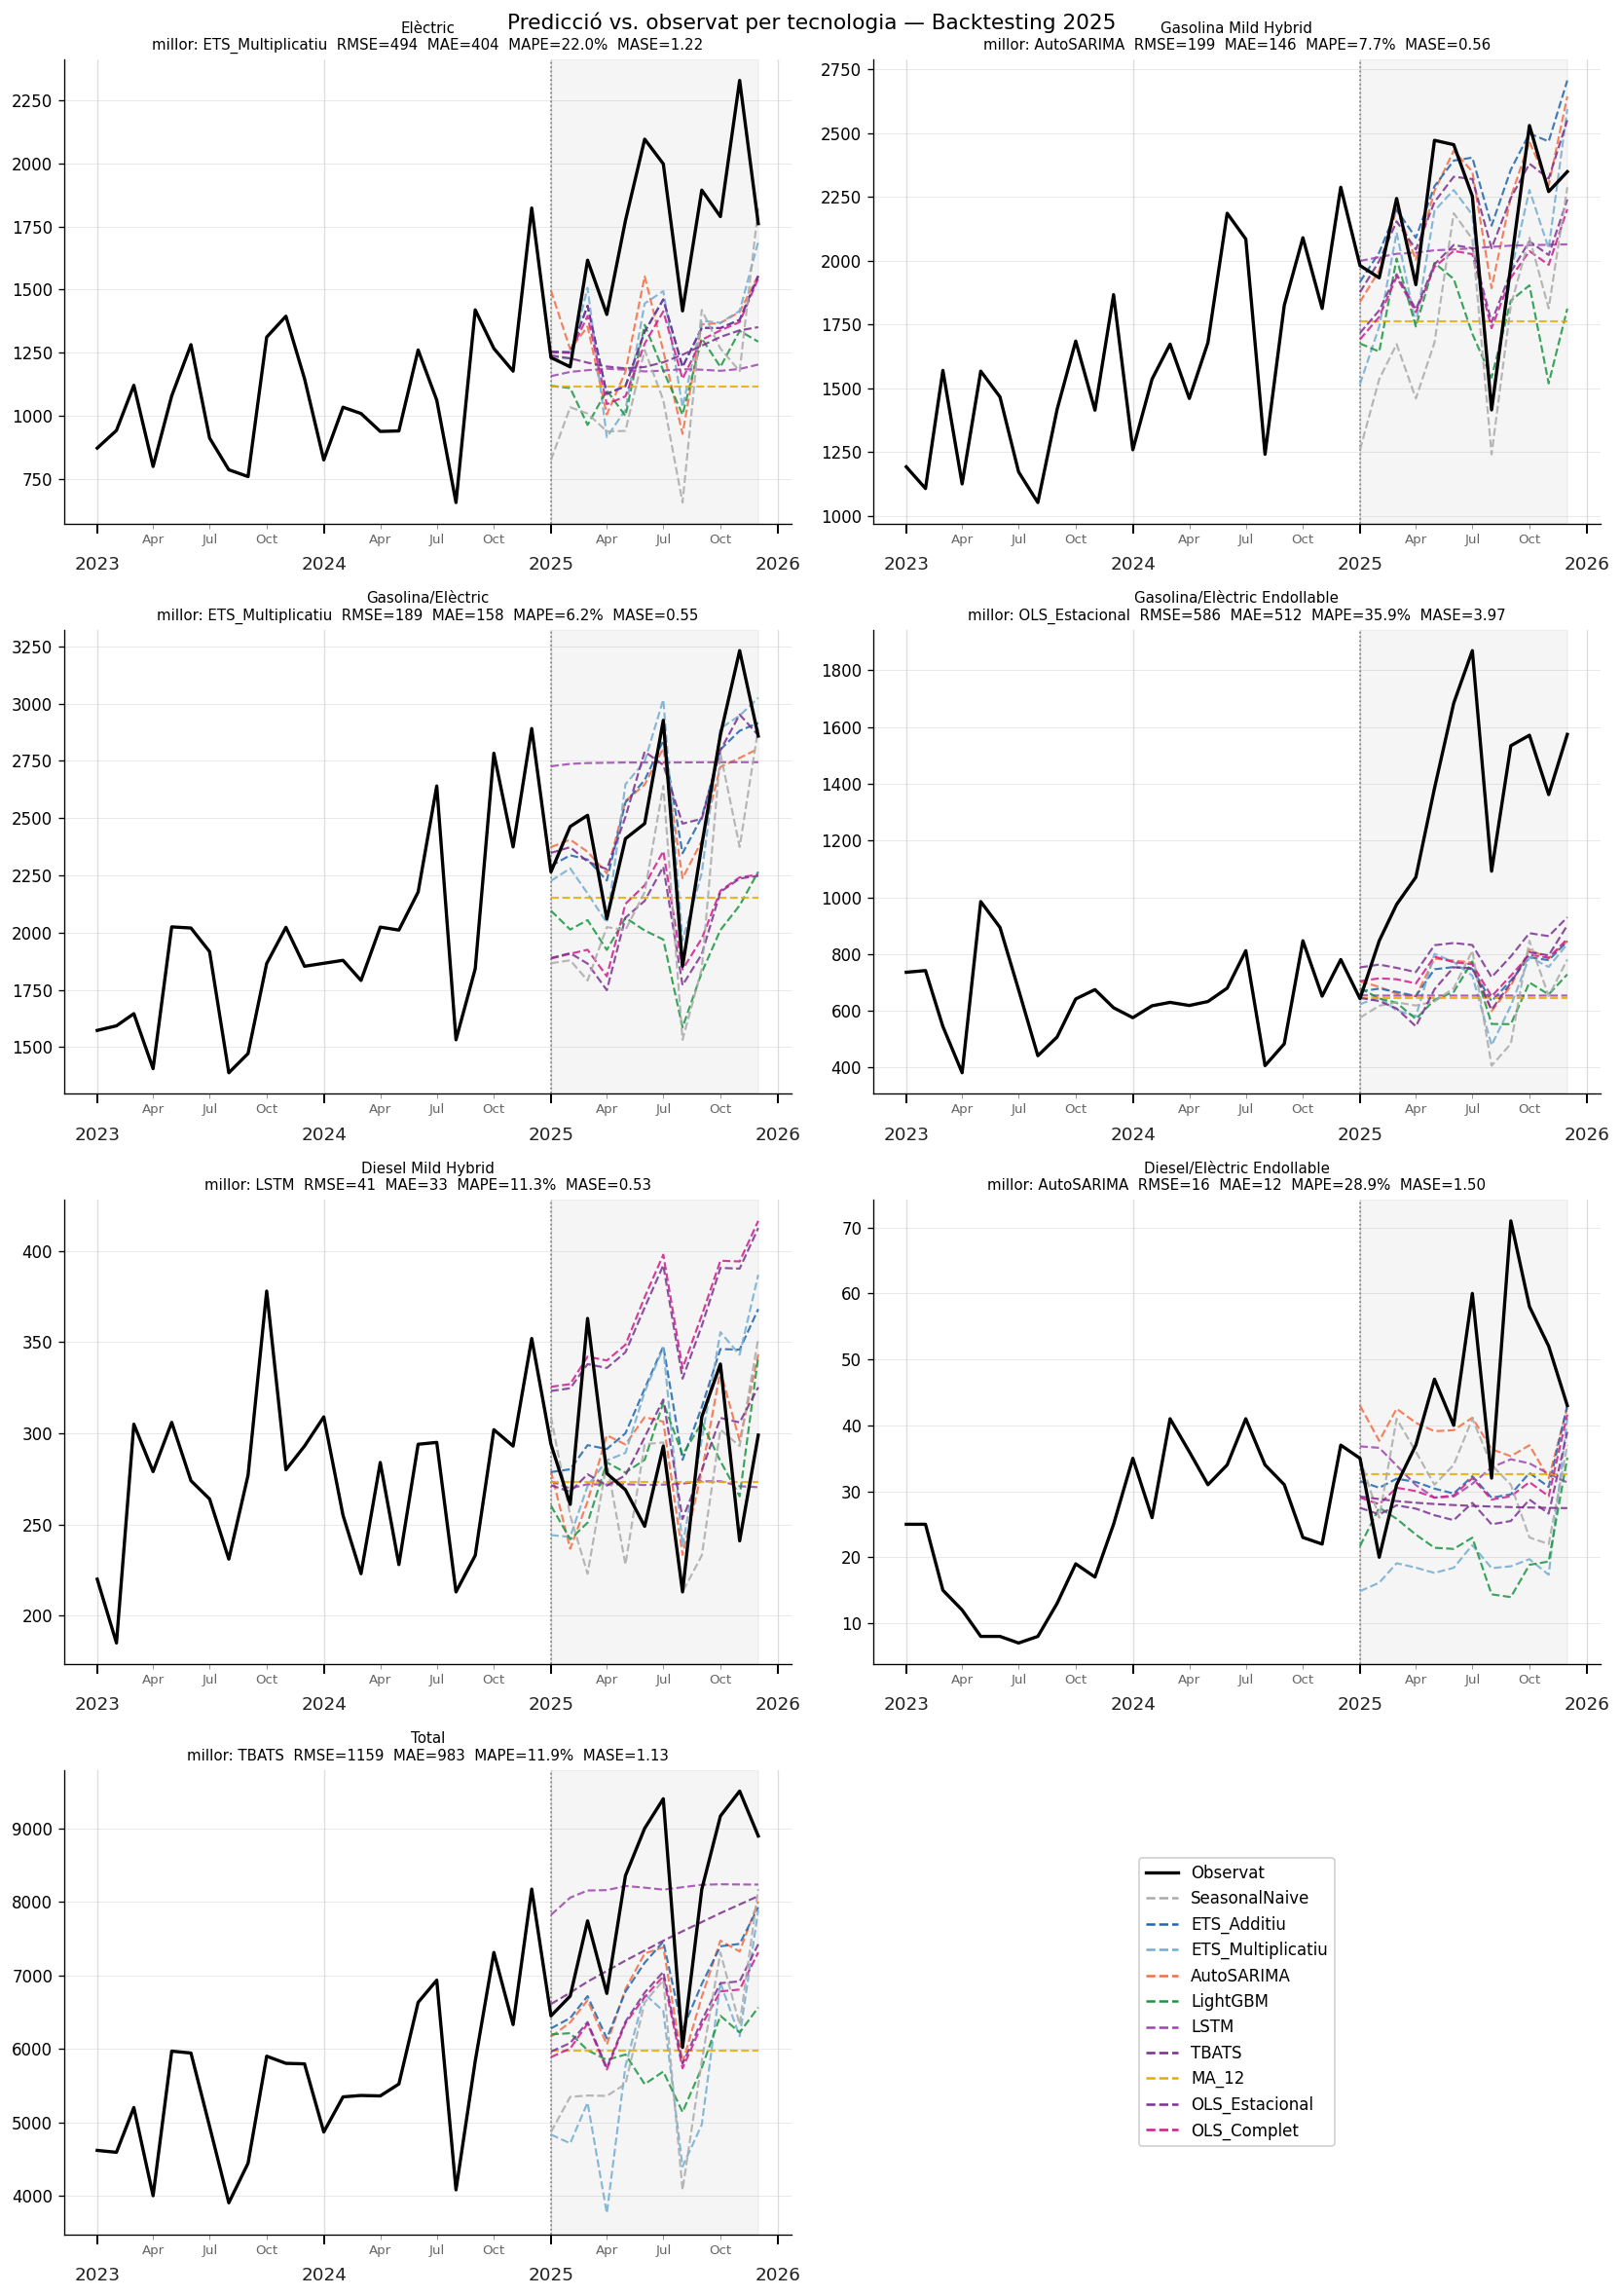

In [6]:
from matplotlib.lines import Line2D

# Millor model per tecnologia (criteri: MASE) per anotar el títol amb les 4 mètriques
best_idx = all_metrics.groupby('Tecnologia')['MASE'].idxmin()
best_per_tech = all_metrics.loc[best_idx].set_index('Tecnologia')

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(TECNOLOGIES):
    ax = axes_flat[i]
    sub_t = all_forecasts[all_forecasts['Tecnologia'] == tech]

    y_train_plot = pivot_train_ev[tech].iloc[-24:]
    y_test_plot  = pivot_test_ev[tech]
    observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
    observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)

    ax.plot(observed_dates, observed_vals, color='black', lw=2, zorder=10)
    ax.axvspan(pivot_test_ev.index[0], pivot_test_ev.index[-1], alpha=0.08, color='gray')
    ax.axvline(pivot_test_ev.index[0], color='gray', ls=':', lw=1)

    for model_name in sorted(sub_t['Model'].unique()):
        msub = sub_t[sub_t['Model'] == model_name].sort_values('date')
        ax.plot(msub['date'], msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', alpha=0.85)

    b = best_per_tech.loc[tech]
    ax.set_title(
        f'{tech}\nmillor: {b["Model"]}  RMSE={b["RMSE"]:.0f}  MAE={b["MAE"]:.0f}  '
        f'MAPE={b["MAPE"]:.1f}%  MASE={b["MASE"]:.2f}', fontsize=9)
    format_ts_ax(ax)

# Últim subplot: llegenda
axes_flat[-1].axis('off')
legend_elements = [Line2D([0], [0], color='black', lw=2, label='Observat')]
for model_name, color in palette.items():
    legend_elements.append(Line2D([0], [0], color=color, lw=1.5, ls='--', label=model_name))
axes_flat[-1].legend(handles=legend_elements, loc='center', fontsize=10, framealpha=0.9)

plt.suptitle('Predicció vs. observat per tecnologia — Backtesting 2025', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_18_comparison_per_tech.png', bbox_inches='tight')
plt.show()

La visualització per tecnologia permet veure d'una sola ullada per què el rànquing numèric queda com queda, i revela patrons que la taula de mètriques amaga.

Gasolina/Elèctric és la tecnologia on tots els models estadístics s'ajusten millor: l'estacionalitat és regular, la tendència és estable i les corbes de predicció s'agrupen prou a prop de la sèrie observada. ETS Multiplicatiu captura especialment bé els pics de primavera perquè l'amplitud de l'oscil·lació creix amb el nivell. Un patró similar apareix a Gasolina Mild Hybrid, on AutoSARIMA segueix de prop la sèrie amb el MASE més baix de tot el benchmark (0.56), i a Diesel Mild Hybrid, on les prediccions estadístiques convergeixen a un rang estret.

Elèctric és el cas on la separació entre models és més visible. La sèrie puja amb força i amb una variabilitat creixent: els models additius (ETS Additiu, AutoSARIMA) tendeixen a quedar per sota als mesos alts de tardor, mentre que ETS Multiplicatiu és el que s'adapta millor a l'amplitud real dels pics, cosa que explica el seu MASE de 1.22 enfront del 1.37 d'AutoSARIMA.

Diesel/Elèctric Endollable presenta prediccions molt disperses entre models. El volum absolut és molt baix (entre 0 i 88 unitats mensuals), de manera que qualsevol petit error en valor absolut es tradueix en un MAPE o MASE elevat. AutoSARIMA queda com el menys dolent (1.50) però la figura mostra que tots els models tenen dificultats per seguir una sèrie tan irregular.

Gasolina/Elèctric Endollable és la que crida l'atenció a primera vista: les prediccions de tots els models s'agrupen molt per sota de la sèrie observada durant el 2025. No és un error de calibratge sinó una ruptura estructural — el creixement del +102% no té precedent en cap any anterior i no hi ha cap senyal a la sèrie que permetés anticipar-lo. Totes les corbes prediuen continuïtat del plateau de 2024, que era el comportament raonable donada la informació disponible.

## 4. Walk-forward validation (rolling-origin)

El rànquing de la secció 2 i les comparacions de la secció 3 es basen en un únic holdout de 12 mesos (gener–desembre 2025), una sola realització de l'error possible. Per validar la robustesa de la comparació, cada notebook de model executa també una validació *walk-forward* amb 13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`), i desa els resultats com a `{model}_wfv_metrics.csv` i `{model}_wfv_forecasts.csv`. Aquí els recollim tots i repetim l'anàlisi.

Procediment estàndard segons Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (cap. 5.10), i emprat a les M-competitions de Makridakis. Aporta una estimació amb molta menys variància que el holdout únic perquè agrega l'error sobre 7 sèries × ~13 folds = ~91 evaluacions per model.

In [7]:
wfv_metric_files   = [f for f in RESULTS_DIR.glob('*_wfv_metrics.csv')
                       if not f.name.startswith('all_')
                       and not _exclude(f.name)]
wfv_forecast_files = [f for f in RESULTS_DIR.glob('*_wfv_forecasts.csv')
                       if not f.name.startswith('all_')
                       and not _exclude(f.name)]
print(f'WFV metrics files: {[f.name for f in wfv_metric_files]}')
print(f'WFV forecast files: {[f.name for f in wfv_forecast_files]}')

if not wfv_metric_files:
    raise FileNotFoundError(
        'No es troben els *_wfv_metrics.csv. Executa primer cada notebook de model.'
    )

wfv_metrics_raw   = pd.concat([pd.read_csv(f, parse_dates=['fold_start'])
                                for f in wfv_metric_files], ignore_index=True)
wfv_forecasts_raw = pd.concat([pd.read_csv(f, parse_dates=['fold_start', 'date'])
                                for f in wfv_forecast_files], ignore_index=True)

wfv_metrics = wfv_metrics_raw.dropna(subset=['MASE']).copy()

wfv_metrics_agg = (wfv_metrics
                   .groupby(['Tecnologia', 'Model'])[METRICS_4]
                   .mean().round(2).reset_index())

print(f'\nFolds vàlids: {len(wfv_metrics)} '
      f'({len(wfv_metrics_raw) - len(wfv_metrics)} folds amb error descartats)')
print(f'Tecnologies × Models: {wfv_metrics_agg.shape[0]} files')

WFV metrics files: ['sarima_wfv_metrics.csv', 'tbats_wfv_metrics.csv', 'lgbm_wfv_metrics.csv', 'lstm_wfv_metrics.csv', 'deterministic_wfv_metrics.csv', 'baseline_wfv_metrics.csv']
WFV forecast files: ['deterministic_wfv_forecasts.csv', 'tbats_wfv_forecasts.csv', 'lgbm_wfv_forecasts.csv', 'baseline_wfv_forecasts.csv', 'sarima_wfv_forecasts.csv', 'lstm_wfv_forecasts.csv']

Folds vàlids: 910 (0 folds amb error descartats)
Tecnologies × Models: 70 files


### Rànquing global WFV vs holdout únic (4 mètriques)

Comparem el ranquing global (mitjana sobre les 7 tecnologies) entre WFV (mitjana de folds) i el holdout únic. Si les barres dels dos colors mantenen el mateix ordre relatiu, el rànquing del holdout es valida.

WFV global (mitjana sobre tecnologies):


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,280.87,233.84,23.70,1.01
TBATS,331.33,271.51,23.44,1.11
OLS_Complet,306.67,261.93,25.58,1.12
AutoSARIMA,306.64,257.11,29.31,1.14
OLS_Estacional,310.82,265.95,25.87,1.14
LSTM,361.99,300.27,24.47,1.19
ETS_Multiplicatiu,383.48,332.19,28.75,1.27
MA_12,407.53,345.57,24.58,1.27
SeasonalNaive,390.73,336.64,26.32,1.30


Holdout 2025 global:


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,435.56,367.87,19.93,1.55
TBATS,418.77,352.45,20.58,1.59
OLS_Complet,555.00,491.41,24.66,1.90
AutoSARIMA,425.25,367.69,19.44,1.49
OLS_Estacional,535.41,473.04,24.52,1.87
LSTM,473.30,405.54,22.70,1.77
ETS_Multiplicatiu,588.80,540.98,25.24,1.94
MA_12,695.12,601.81,25.37,2.09
SeasonalNaive,645.03,587.54,25.91,2.06


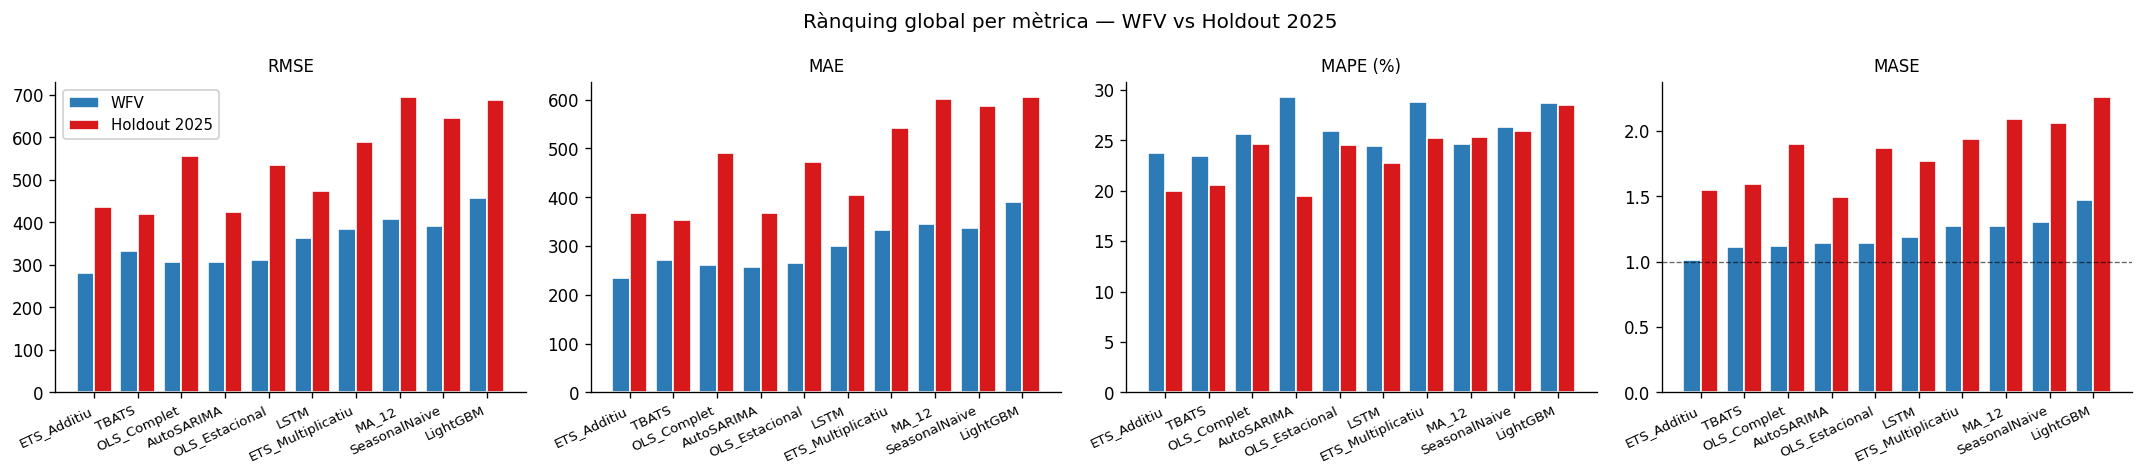

In [8]:
wfv_global = (wfv_metrics_agg.groupby('Model')[METRICS_4].mean().round(2)
              .sort_values('MASE'))
hold_global = (all_metrics[all_metrics['Model'].isin(wfv_global.index)]
               .groupby('Model')[METRICS_4].mean().round(2))
print('WFV global (mitjana sobre tecnologies):')
display(wfv_global)
print('Holdout 2025 global:')
display(hold_global.reindex(wfv_global.index))

# Bar chart: 4 subplots, 2 grups per model (WFV vs holdout)
models_order = wfv_global.index.tolist()
x = np.arange(len(models_order))
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, metric in zip(axes, METRICS_4):
    ax.bar(x - 0.2, wfv_global.loc[models_order, metric].values, width=0.4,
           label='WFV', color='#2c7bb6', edgecolor='white')
    ax.bar(x + 0.2, hold_global.reindex(models_order)[metric].values, width=0.4,
           label='Holdout 2025', color='#d7191c', edgecolor='white')
    ax.set_xticks(x)
    ax.set_xticklabels(models_order, rotation=25, ha='right', fontsize=8)
    ax.set_title(f'{metric}' + (' (%)' if metric == 'MAPE' else ''), fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if metric == 'MASE':
        ax.axhline(1.0, color='black', ls='--', lw=0.8, alpha=0.6)
axes[0].legend(fontsize=9, framealpha=0.9)
plt.suptitle('Rànquing global per mètrica — WFV vs Holdout 2025', fontsize=12)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_19_wfv_vs_holdout.png', bbox_inches='tight')
plt.show()

### Mètriques WFV mitjanes per tecnologia

Per a cada tecnologia, taula amb les 4 mètriques mitjanes sobre els 13 folds. El millor model de cada columna queda destacat. És el nucli numèric de l'avaluació WFV.

In [9]:
# Només taules (sense bar-charts: ja tenim el ranquing global a la figura anterior)
for tech in TECNOLOGIES:
    sub = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == tech]
           .set_index('Model')[METRICS_4].round(2)
           .sort_values('MASE'))
    if len(sub) == 0:
        continue
    print(f'\n— {tech} —')
    display(sub.style.highlight_min(axis=0, props='font-weight:bold; color:#1a9641'))


— Elèctric —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,306.670000,257.790000,23.840000,0.720000
OLS_Complet,302.830000,254.930000,22.770000,0.720000
OLS_Estacional,306.700000,257.820000,23.840000,0.720000
MA_12,330.250000,270.260000,21.260000,0.770000
LSTM,337.140000,277.930000,23.640000,0.780000
TBATS,337.870000,277.860000,23.550000,0.780000
ETS_Multiplicatiu,348.690000,291.800000,27.340000,0.810000
LightGBM,352.580000,295.100000,24.380000,0.840000
SeasonalNaive,363.660000,300.310000,24.530000,0.850000



— Gasolina Mild Hybrid —


,RMSE,MAE,MAPE,MASE
Model,,,,
AutoSARIMA,216.420000,178.240000,11.870000,0.740000
ETS_Multiplicatiu,226.210000,179.990000,11.860000,0.750000
OLS_Estacional,226.920000,191.700000,11.770000,0.790000
ETS_Additiu,235.530000,194.160000,12.690000,0.800000
OLS_Complet,238.950000,203.820000,12.720000,0.840000
TBATS,259.350000,207.930000,13.700000,0.860000
LSTM,319.490000,262.990000,15.980000,1.090000
SeasonalNaive,377.310000,322.810000,19.300000,1.330000
MA_12,403.700000,343.970000,19.690000,1.410000



— Gasolina/Elèctric —


...

,RMSE,MAE,MAPE,MASE
Model,,,,
MA_12,47.790000,39.180000,15.020000,0.600000
TBATS,51.430000,41.750000,16.410000,0.640000
LSTM,51.780000,42.240000,16.430000,0.650000
ETS_Additiu,53.060000,44.520000,18.060000,0.680000
SeasonalNaive,61.550000,47.510000,17.650000,0.730000
ETS_Multiplicatiu,60.880000,49.120000,18.980000,0.750000
LightGBM,61.400000,49.090000,18.040000,0.750000
AutoSARIMA,60.100000,49.860000,19.730000,0.760000
OLS_Estacional,73.960000,65.120000,26.910000,1.010000



— Diesel/Elèctric Endollable —


,RMSE,MAE,MAPE,MASE
Model,,,,
OLS_Complet,11.790000,9.470000,61.930000,1.360000
ETS_Additiu,12.150000,9.930000,61.880000,1.440000
OLS_Estacional,12.570000,10.060000,62.960000,1.440000
MA_12,12.430000,10.490000,54.880000,1.510000
TBATS,12.740000,10.710000,52.890000,1.540000
LSTM,12.850000,10.930000,55.350000,1.570000
SeasonalNaive,13.920000,11.240000,59.820000,1.630000
AutoSARIMA,15.410000,12.270000,83.880000,1.790000
LightGBM,15.530000,13.090000,63.400000,1.860000



— Total —


,RMSE,MAE,MAPE,MASE
Model,,,,
ETS_Additiu,805.580000,676.510000,11.210000,0.790000
AutoSARIMA,826.310000,702.870000,11.880000,0.820000
OLS_Complet,859.800000,733.370000,11.850000,0.860000
OLS_Estacional,857.490000,732.490000,11.950000,0.860000
TBATS,1045.520000,854.720000,15.170000,1.000000
LSTM,1121.510000,935.890000,15.920000,1.100000
SeasonalNaive,1204.250000,1077.860000,17.670000,1.260000
MA_12,1335.920000,1151.460000,18.500000,1.350000
LightGBM,1494.060000,1280.270000,20.860000,1.500000


### Variabilitat de l'error entre folds (boxplot)

La taula anterior mostra la mitjana del MASE sobre folds, però amaga la dispersió. Aquest boxplot mostra la distribució del MASE sobre els 91 folds totals per model (13 origins × 7 tecnologies). Una caixa estreta indica un model **consistent**: l'error és estable encara que canviï l'origin. Una caixa ampla indica un model **inestable**: alguns folds funcionen bé i d'altres molt malament. Els models amb caixa estreta i mediana baixa són els més fiables per a producció.

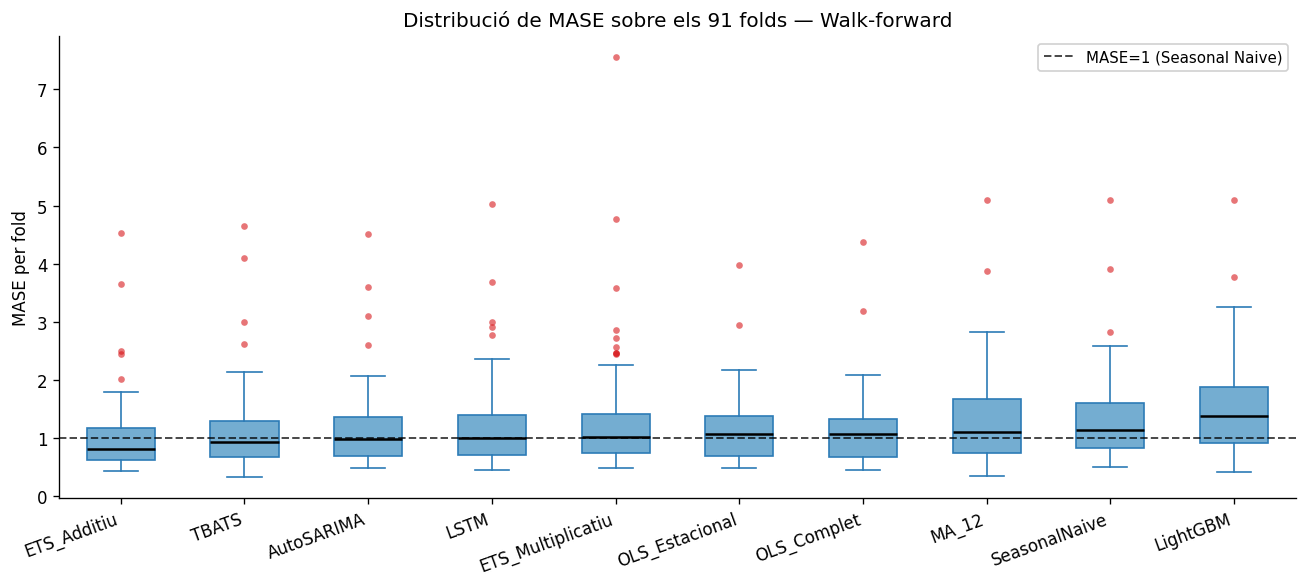

Estadístiques de MASE per model (sobre 91 folds):


,median,mean,std,pct_<1
Model,,,,
ETS_Additiu,0.81,1.01,0.63,61.54
TBATS,0.93,1.11,0.70,58.24
AutoSARIMA,0.98,1.14,0.66,50.55
LSTM,1.00,1.19,0.74,49.45
ETS_Multiplicatiu,1.02,1.27,0.98,47.25
OLS_Complet,1.06,1.12,0.59,47.25
OLS_Estacional,1.06,1.14,0.57,46.15
MA_12,1.10,1.27,0.76,43.96
SeasonalNaive,1.13,1.30,0.71,39.56


In [10]:
order_box = wfv_metrics.groupby('Model')['MASE'].median().sort_values().index.tolist()
positions = np.arange(len(order_box))

fig, ax = plt.subplots(figsize=(11, 5))
data = [wfv_metrics[wfv_metrics['Model'] == m]['MASE'].values for m in order_box]
bp = ax.boxplot(data, positions=positions, widths=0.55, patch_artist=True,
                medianprops=dict(color='black', lw=1.5),
                boxprops=dict(facecolor='#74add1', edgecolor='#2c7bb6'),
                whiskerprops=dict(color='#2c7bb6'),
                capprops=dict(color='#2c7bb6'),
                flierprops=dict(marker='o', markersize=4, markerfacecolor='#d7191c',
                                markeredgecolor='none', alpha=0.6))
ax.axhline(1.0, color='black', ls='--', lw=1.2, alpha=0.7, label='MASE=1 (Seasonal Naive)')
ax.set_xticks(positions)
ax.set_xticklabels(order_box, rotation=20, ha='right')
ax.set_ylabel('MASE per fold')
ax.set_title('Distribució de MASE sobre els 91 folds — Walk-forward', fontsize=12)
ax.legend(fontsize=9, framealpha=0.9)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_20_wfv_boxplot.png', bbox_inches='tight')
plt.show()

# Estadístiques de dispersió
disp = (wfv_metrics.groupby('Model')['MASE']
        .agg(['median', 'mean', 'std',
              ('pct_<1', lambda x: (x < 1.0).mean() * 100)])
        .round(2).sort_values('median'))
print('Estadístiques de MASE per model (sobre 91 folds):')
display(disp)

### Sèries h=1 per tecnologia (tots els models)

Per a cada tecnologia, sèrie real al fons + una línia per model amb la predicció a un mes vista a cada origin (13 punts per model). Aquesta visualització mostra l'ancoratge de la predicció al nivell real: si la dashed segueix bé la línia blava, el model captura bé el nivell mes a mes. Per evitar la sopa de 156 prediccions per subplot, restringim a h=1 — els errors a horitzons llargs ja queden recollits per les mètriques agregades.

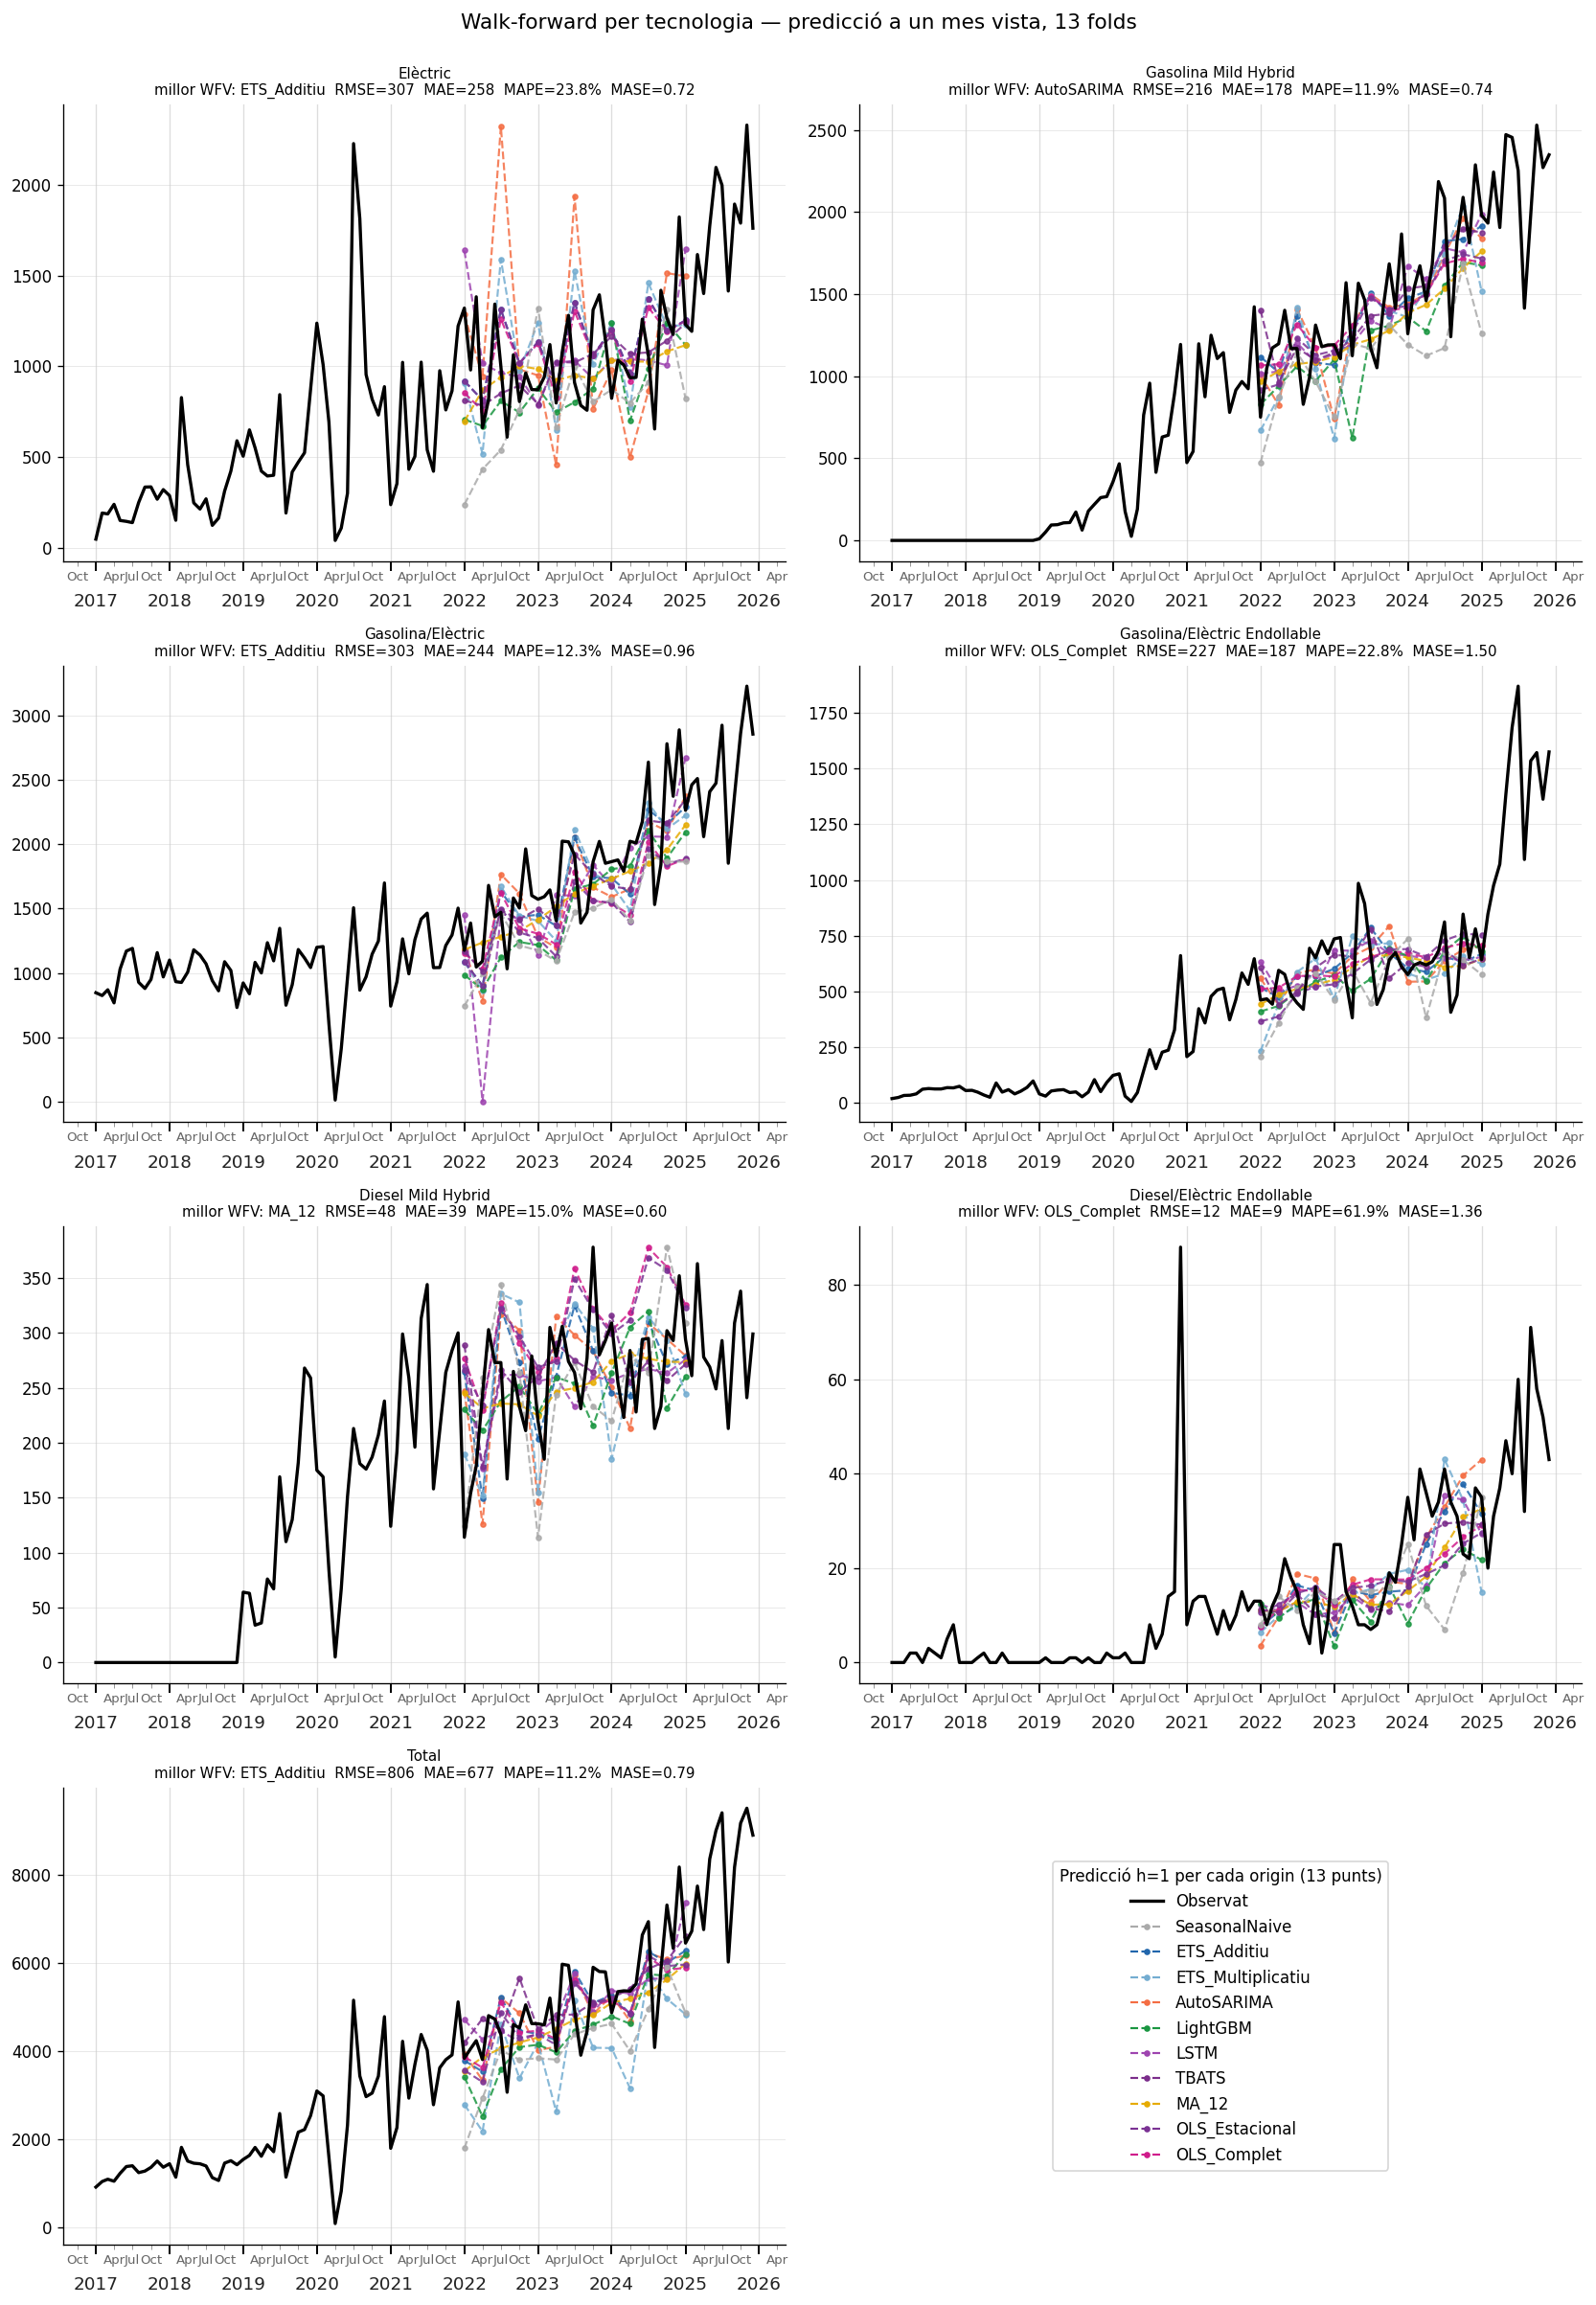

In [11]:
pivot_full_ev = pd.concat([pivot_train_ev, pivot_test_ev]).sort_index()

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
axes_flat = axes.flatten()

for i, tech in enumerate(TECNOLOGIES):
    ax = axes_flat[i]
    s = pivot_full_ev[tech]
    ax.plot(s.index, s.values, color='black', lw=2, zorder=10)

    sub = wfv_forecasts_raw[
        (wfv_forecasts_raw['Tecnologia'] == tech)
        & (wfv_forecasts_raw['h'] == 1)
    ]
    for model_name in sorted(sub['Model'].unique()):
        msub = sub[sub['Model'] == model_name].sort_values('date')
        ax.plot(pd.to_datetime(msub['date']), msub['predicted'],
                color=palette.get(model_name, '#888888'),
                lw=1.3, ls='--', marker='o', ms=3, alpha=0.85)

    best = (wfv_metrics_agg[wfv_metrics_agg['Tecnologia'] == tech]
            .sort_values('MASE').iloc[0])
    ax.set_title(
        f'{tech}\nmillor WFV: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
        f'MAE={best["MAE"]:.0f}  MAPE={best["MAPE"]:.1f}%  MASE={best["MASE"]:.2f}',
        fontsize=9)
    format_ts_ax(ax)

axes_flat[-1].axis('off')
legend = [Line2D([0], [0], color='black', lw=2, label='Observat')]
for model_name, c in palette.items():
    if model_name in wfv_metrics_agg['Model'].unique():
        legend.append(Line2D([0], [0], color=c, lw=1.3, ls='--', marker='o',
                             ms=3, label=model_name))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=10,
                     title='Predicció h=1 per cada origin (13 punts)')

plt.suptitle('Walk-forward per tecnologia — predicció a un mes vista, 13 folds',
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_21_wfv_series_per_tech.png', bbox_inches='tight')
plt.show()

In [12]:
summary.reset_index().to_csv(RESULTS_DIR / 'model_ranking.csv', index=False)
all_metrics.to_csv(RESULTS_DIR / 'all_metrics.csv', index=False)
wfv_metrics.to_csv(RESULTS_DIR / 'all_wfv_metrics.csv', index=False)
wfv_metrics_agg.to_csv(RESULTS_DIR / 'all_wfv_metrics_agg.csv', index=False)
print('Guardats: model_ranking.csv, all_metrics.csv, all_wfv_metrics.csv, all_wfv_metrics_agg.csv')

Guardats: model_ranking.csv, all_metrics.csv, all_wfv_metrics.csv, all_wfv_metrics_agg.csv


## 5. Conclusions

El benchmark deixa cinc conclusions principals que cal llegir de forma conjunta: quin model funciona millor en el holdout 2025, què passa quan validem amb walk-forward, per quina raó el patró és el que és, on residuen els límits estructurals del problema, i quin rol juguen els models deterministes.

**Holdout 2025 vs walk-forward.** El rànquing global canvia substancialment entre les dues avaluacions. Sota el holdout únic (2025), AutoSARIMA encapçala (MASE=1.49), seguit per ETS Additiu (1.55), TBATS (1.59) i LSTM (1.77). Sota WFV (mitjana de 91 folds = 13 origins × 7 sèries), l'ordre canvia dràsticament: **ETS Additiu passa al primer lloc (MASE=1.01)**, seguit per TBATS (1.11), **OLS_Complet (1.12)**, AutoSARIMA (1.14), OLS_Estacional (1.14) i LSTM (1.19). Tots els models milloren significativament respecte al holdout, cosa que confirma que el 2025 va ser un fold particularment difícil — l'acceleració del +34% YoY el va convertir en una observació extrema. La lectura clau és: AutoSARIMA va guanyar el 2025 més per característiques específiques de l'any que per ser el millor model en condicions promig. L'ETS Additiu és el model més robust sobre múltiples horitzons. LightGBM es manté com el pitjor entre els estadístics i ML en tots dos rànquings (holdout 2.26, WFV 1.47), confirmant que el gradient boosting no és competitiu amb N≈84 i estacionalitat anual.

**Models deterministes: referència i sorpresa.** Els models deterministes (MA_12, OLS_Estacional, OLS_Complet) tanquen la meitat inferior del rànquing holdout (2.09, 1.87, 1.90), per davant del SeasonalNaive (2.06) i LightGBM (2.26) però lluny dels millors estadístics. La sorpresa arriba al WFV: OLS_Complet (1.12) i OLS_Estacional (1.14) passen al 3r i 5è lloc, per davant d'AutoSARIMA, LSTM i ETS_Multiplicatiu. Això mostra que una regressió OLS amb tendència + dummies estacionals + dummies d'intervenció (COVID, MOVES III) és molt competitiva en horitzons promig quan no hi ha ruptures estructurals. El seu desavantatge apareix el 2025 — l'any on la tendència lineal no capta l'acceleració.

**Selecció de model per tecnologia.** Cap model no guanya a totes les tecnologies alhora. ETS Multiplicatiu és el millor per a Elèctric i Gasolina/Elèctric (estacionalitat proporcional al nivell). AutoSARIMA i TBATS dominen les tecnologies amb dinàmica estable. En WFV, MA_12 guanya a Diesel Mild Hybrid (una sèrie molt regular), i OLS_Complet guanya a Diesel/Elèctric Endollable i Gas/Elèctric Endollable, on les dummies d'intervenció capturen canvis de règim. L'estratègia recomanada és heterogènia: ETS Additiu per a robustesa global, ETS Multiplicatiu per a sèries de creixement accelerat, OLS_Complet per a tecnologies molt influenciades per polítiques d'incentiu.

**Per què guanyen els estadístics.** Els tres primers del rànquing WFV (ETS Additiu, TBATS, OLS_Complet) combinen pocs paràmetres amb una captura explícita de l'estacionalitat. La literatura de les competicions M (Makridakis et al., 2020) documenta que amb menys de 100 observacions i estacionalitat anual ben marcada, els mètodes estadístics de pocs paràmetres superen els de machine learning. LightGBM no aconsegueix superar el Seasonal Naive ni sota WFV (1.47 vs 1.30) perquè el gradient boosting necessita centenars de mostres per aprendre l'estacionalitat de forma implícita. El LSTM en canvi sí supera el SN sota WFV (1.19 vs 1.30) i és el cas més clar on l'avaluació WFV redimensiona el judici: el holdout del 2025 el penalitzava més del compte.

**Subestimació estructural del 2025.** Un resultat transversal del holdout: tots els models prediuen per sota de l'observat, amb biaixos d'entre el 6% i el 14% sobre el Total. No és un error de modelització corregible ajustant paràmetres. El 2025 va créixer un 34% YoY, molt per sobre de la tendència històrica, i això revela que el mercat seguia en una fase d'acceleració estructural que cap sèrie temporal univariant no pot anticipar sense informació exògena (expansió de la xarxa de càrrega, reducció de preus dels EV, anuncis de política industrial). El WFV ho confirma indirectament: els MASE WFV són significativament menors que els del holdout 2025 per a tots els models (per exemple, AutoSARIMA passa d'1.49 a 1.14), perquè els folds anteriors al 2025 estaven en períodes de tendència més regular.

**Anomalia de Gasolina/Elèctric Endollable.** La PHEV és el principal factor que infla les mètriques globals. Cap model no baixa del 40% de MAPE en aquesta tecnologia: el PHEV ha crescut a través de quatre règims distints marcats per l'activació i l'esgotament successiu dels plans MOVES. El 2024 va tancar amb un plateau (−1%) i el 2025 va saltar un +102%. Cap model de sèries temporals no pot capturar aquest mecanisme sense les dates d'obertura i tancament de cada convocatòria com a variables exògenes.

En síntesi, el projecte estableix un benchmark reproduïble sobre la demanda de vehicles electrificats a Catalunya per al 2017–2025, validat tant amb holdout únic com amb walk-forward. Amb les dues avaluacions sobre la taula, **l'ETS Additiu emergeix com el model més consistent globalment**, seguit de TBATS i, sorprenentment, OLS_Complet. El límit principal del benchmark no és metodològic sinó informatiu: sense dades sobre polítiques d'incentius i infraestructura, cap sèrie temporal univariant no pot capturar del tot les acceleracions del mercat.